## 1. Selección del dataset

AI4I 2020 (UCI) permite estudiar la predicción binaria de `Machine failure` para mantenimiento predictivo. Sus temperaturas, velocidad, torque y desgaste justifican un problema análogo al mantenimiento de maquinaria agropecuaria. Son datos industriales sintéticos: este encuadre didáctico no demuestra validez operativa agrícola.

Fuente: [página UCI](https://archive.ics.uci.edu/dataset/601/ai4i+2020+predictive+maintenance+dataset). Descarga oficial: https://archive.ics.uci.edu/static/public/601/ai4i+2020+predictive+maintenance+dataset.zip.

Licencia: CC BY 4.0. Cita: Matzka, S. (2020). AI4I 2020 Predictive Maintenance Dataset. UCI Machine Learning Repository. https://doi.org/10.24432/C5HS5C.

Notebook generado desde Python; los resultados ya están incorporados. Para volver a ejecutar las celdas, instalar el runtime con `uv sync --extra notebook` (IPython e ipykernel), seleccionar `.venv/bin/python` como kernel y usar la raíz del repositorio como directorio de trabajo, no `notebooks/`.

In [1]:
from pathlib import Path
from pprint import pprint

import polars as pl

from agrofail import config, eda
from agrofail.load import load_dataset

raw = load_dataset()
pprint({'shape': raw.shape, 'target': config.TARGET_COLUMN})

{'shape': (10000, 14), 'target': 'Machine failure'}

## 2. Análisis exploratorio inicial (EDA)

Se inspeccionan dimensiones, tipos, valores faltantes (nulos y NaN), estadísticas descriptivas y balance de clases. Los histogramas muestran las distribuciones de sensores; el mapa de calor resume correlaciones de Pearson. Correlación no implica causalidad ni utilidad predictiva. Esta exploración no ajusta parámetros de transformación.

{'row_count': 10000,
 'column_count': 14,
 'columns': {'UDI': {'dtype': 'Int64', 'missing_count': 0},
             'Product ID': {'dtype': 'String', 'missing_count': 0},
             'Type': {'dtype': 'String', 'missing_count': 0},
             'Air temperature [K]': {'dtype': 'Float64', 'missing_count': 0},
             'Process temperature [K]': {'dtype': 'Float64',
                                         'missing_count': 0},
             'Rotational speed [rpm]': {'dtype': 'Int64', 'missing_count': 0},
             'Torque [Nm]': {'dtype': 'Float64', 'missing_count': 0},
             'Tool wear [min]': {'dtype': 'Int64', 'missing_count': 0},
             'Machine failure': {'dtype': 'Int64', 'missing_count': 0},
             'TWF': {'dtype': 'Int64', 'missing_count': 0},
             'HDF': {'dtype': 'Int64', 'missing_count': 0},
             'PWF': {'dtype': 'Int64', 'missing_count': 0},
             'OSF': {'dtype': 'Int64', 'missing_count': 0},
             'RNF': {'dtype': 'Int

column,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
str,f64,f64,f64,f64,f64
"""Air temperature [K]""",1.0,0.876107,0.02267,-0.013778,0.013853
"""Process temperature [K]""",0.876107,1.0,0.019277,-0.014061,0.013488
"""Rotational speed [rpm]""",0.02267,0.019277,1.0,-0.875027,0.000223
"""Torque [Nm]""",-0.013778,-0.014061,-0.875027,1.0,-0.003093
"""Tool wear [min]""",0.013853,0.013488,0.000223,-0.003093,1.0


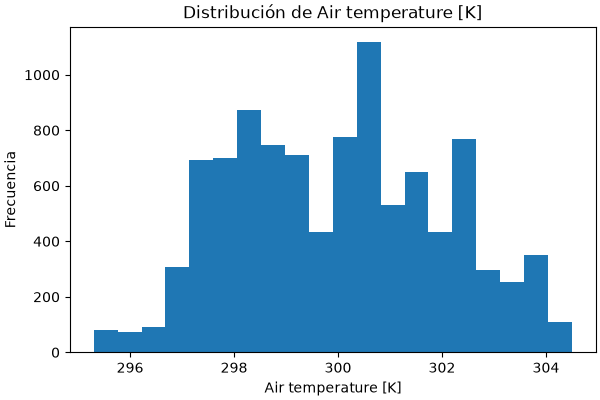

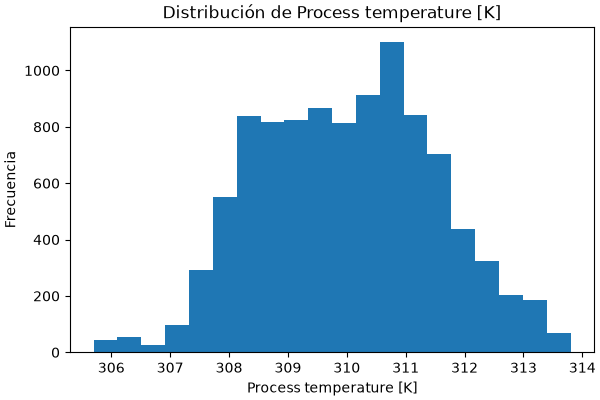

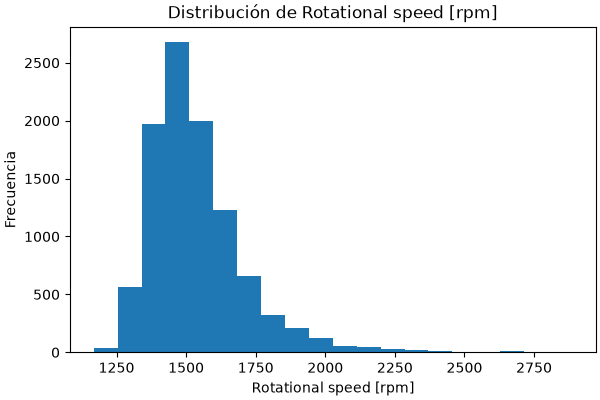

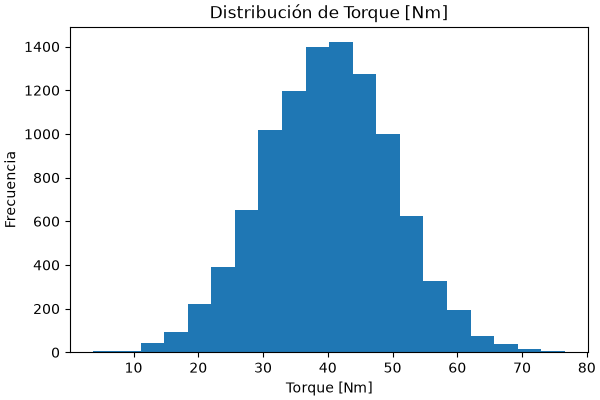

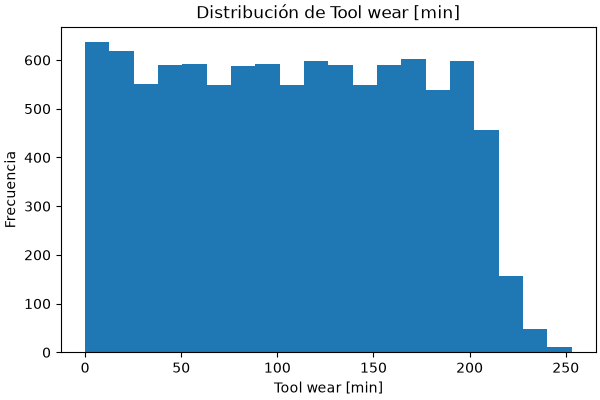

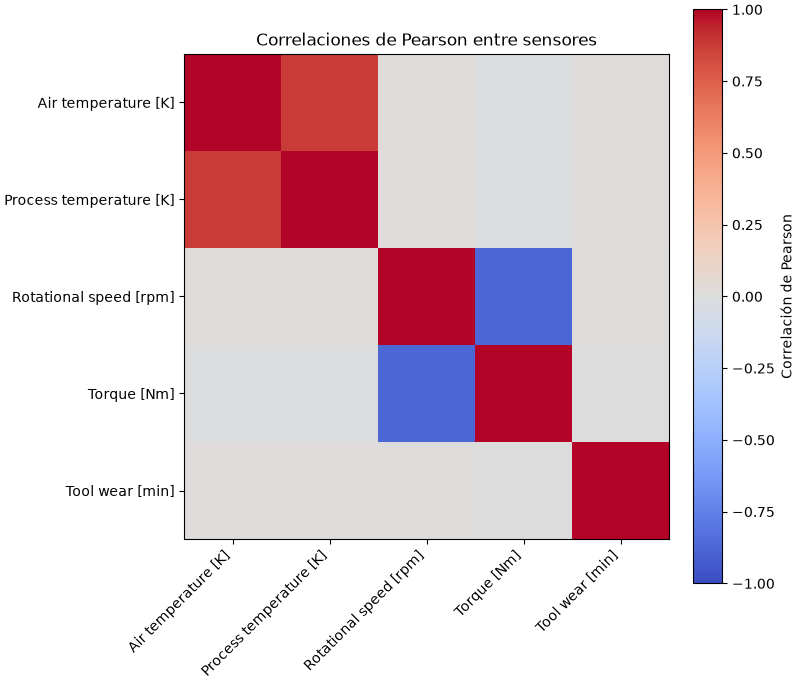

In [2]:
from IPython.display import Image, display

pprint(eda.summarise(raw))
print(eda.correlation_matrix(raw))
figure_dir = Path('notebooks/figures')
figures = eda.plot_distributions(raw, figure_dir, language='es')
figures.append(eda.plot_correlation_heatmap(raw, figure_dir, language='es'))
for path in figures:
    display(Image(filename=str(path)))

## 3. Limpieza de datos

Se eliminan duplicados exactos conservando la primera fila y se descartan filas con nulos en sensores, tipo u objetivo, sin imputación. Esta política no trata NaN como nulo: los sensores no finitos fallan en la transformación. Los valores atípicos se reportan mediante límites IQR (1,5 veces el rango intercuartílico), pero no se eliminan ni recortan: pueden indicar fallas. Los conteos por sensor pueden solaparse; se informa también el total de filas. La pérdida por faltantes debe revisarse por posible sesgo de selección.

In [3]:
from agrofail.clean import clean, detect_outliers, drop_duplicates

cleaned = clean(raw)
pprint({'input_rows': raw.height,
        'duplicates_removed': raw.height - drop_duplicates(raw).height,
        'rows_dropped_missing': drop_duplicates(raw).height - cleaned.height,
        'remaining_rows': cleaned.height,
        'outlier_rows_retained': detect_outliers(cleaned).height,
        'outliers_by_sensor': {name: detect_outliers(cleaned, [name]).height
                               for name in config.NUMERIC_COLUMNS}})

{'input_rows': 10000,
 'duplicates_removed': 0,
 'rows_dropped_missing': 0,
 'remaining_rows': 10000,
 'outlier_rows_retained': 459,
 'outliers_by_sensor': {'Air temperature [K]': 0,
                        'Process temperature [K]': 0,
                        'Rotational speed [rpm]': 418,
                        'Torque [Nm]': 69,
                        'Tool wear [min]': 0}}

## 4. Transformaciones básicas

Aunque la división se presenta en la sección 6, se realiza ANTES del ajuste. Se ajustan categorías y escalas solo con entrenamiento y se aplican al test sin reajuste. One-hot evita imponer un orden a `Type`; categorías nuevas se representan con ceros. StandardScaler centra y escala sensores según media y desviación de entrenamiento. Se muestran filas antes/después y parámetros aprendidos. Se excluyen identificadores, modos de falla y columnas no configuradas mediante selección de dominio sobre las columnas originales (justificada en la sección 5); el objetivo permanece como etiqueta.

In [4]:
from agrofail.features import apply_encode_and_scale, fit_encode_and_scale
from agrofail.select import select_features
from agrofail.split import split

train_raw, test_raw = split(cleaned)
train_selected = select_features(train_raw)
test_selected = select_features(test_raw)
transformer = fit_encode_and_scale(train_selected)
train_encoded = apply_encode_and_scale(train_selected, transformer)
test_encoded = apply_encode_and_scale(test_selected, transformer)
print(train_raw.head())
print(train_encoded.head())
print(test_encoded.head())
pprint({'sensor_means': transformer.scaler.mean_.tolist(),
        'sensor_scales': transformer.scaler.scale_.tolist(),
        'categories': transformer.encoder.categories_[0].tolist(),
        'excluded_columns': [c for c in train_raw.columns
                             if c not in train_selected.columns],
        'encoded_columns': {'Type': [c for c in transformer.output_columns
                                     if c.startswith('Type_')]}})

UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
i64,str,str,f64,f64,i64,f64,i64,i64,i64,i64,i64,i64,i64
4059,"""M18918""","""M""",302.0,310.9,1456,47.2,54,0,0,0,0,0,0
1222,"""M16081""","""M""",297.0,308.3,1399,46.4,132,0,0,0,0,0,1
6896,"""M21755""","""M""",301.0,311.6,1357,45.6,137,0,0,0,0,0,0
9864,"""L57043""","""L""",298.9,309.8,1411,56.3,84,0,0,0,0,0,0
8712,"""L55891""","""L""",297.1,308.5,1733,28.7,50,0,0,0,0,0,0


Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Type_H,Type_L,Type_M,Machine failure
f64,f64,f64,f64,f64,f64,f64,f64,i64
0.998914,0.604282,-0.460607,0.718305,-0.843997,0.0,0.0,1.0,0
-1.505194,-1.15326,-0.775574,0.638456,0.382263,0.0,0.0,1.0,0
0.498092,1.077466,-1.007654,0.558607,0.46087,0.0,0.0,1.0,0
-0.553633,-0.139294,-0.709265,1.626586,-0.372359,0.0,1.0,0.0,0
-1.455112,-1.018064,1.070019,-1.128202,-0.906882,0.0,1.0,0.0,0


Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Type_H,Type_L,Type_M,Machine failure
f64,f64,f64,f64,f64,f64,f64,f64,i64
0.247681,-0.139294,-1.073963,2.265378,0.71241,0.0,1.0,0.0,0
1.85031,1.618248,-0.145641,0.009646,0.429427,0.0,1.0,0.0,0
1.249324,0.94227,0.108543,-0.239882,1.592802,0.0,1.0,0.0,0
-2.206344,-2.505215,-0.167744,-0.419543,-0.74967,1.0,0.0,0.0,0
0.247681,-0.004098,-1.002129,2.035812,-0.089376,1.0,0.0,0.0,0


{'sensor_means': [300.00545, 310.0060625, 1539.356875, 40.0033625, 107.685],
 'sensor_scales': [1.996719258558899,
                   1.4793392092734339,
                   180.9716311061885,
                   10.018919350089297,
                   63.608026419627265],
 'categories': ['H', 'L', 'M'],
 'excluded_columns': ['UDI', 'Product ID', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF'],
 'encoded_columns': {'Type': ['Type_H', 'Type_L', 'Type_M']}}

## 5. Selección de variables

La tabla presenta la política de dominio y sus razones: conservar sensores y tipo; excluir identificadores y modos de falla para evitar fuga de información. El objetivo se conserva como etiqueta, nunca como predictor. La varianza y correlación en entrenamiento son diagnósticos, no reglas automáticas de eliminación. No se inventan variables derivadas ni importancias de modelos.

In [5]:
from agrofail.report import selection_presentation
from agrofail.select import selection_rationale

rationale = selection_rationale(train_raw)
decisions, diagnostics = selection_presentation(rationale)
with pl.Config(tbl_rows=-1, tbl_cols=-1, fmt_str_lengths=200):
    display(decisions)
pprint(diagnostics)
train, test = train_encoded, test_encoded

column,decision,reason
str,str,str
"""Air temperature [K]""","""conservada""","""Las condiciones térmicas ambientales afectan la refrigeración y la temperatura operativa."""
"""Process temperature [K]""","""conservada""","""La temperatura del proceso describe el calor operativo, distinto del ambiente."""
"""Rotational speed [rpm]""","""conservada""","""La velocidad de rotación describe el régimen operativo de la máquina."""
"""Torque [Nm]""","""conservada""","""El torque mide la carga y el esfuerzo mecánico."""
"""Tool wear [min]""","""conservada""","""El desgaste de la herramienta mide la degradación acumulada."""
"""Type""","""conservada""","""Type representa la calidad del producto; se codifica solo con entrenamiento."""
"""Machine failure""","""conservada""","""Objetivo conservado como etiqueta, no como predictor."""
"""UDI""","""excluida""","""Identificador excluido: la identidad del registro no es un predictor físico."""
"""Product ID""","""excluida""","""Identificador excluido: la identidad del registro no es un predictor físico."""


{'variances': {'Air temperature [K]': 3.986887797499996,
               'Process temperature [K]': 2.1884444960937466,
               'Rotational speed [rpm]': 32750.731265234375,
               'Torque [Nm]': 100.37874494359374,
               'Tool wear [min]': 4045.9810249999987},
 'correlations': {('Air temperature [K]', 'Process temperature [K]'): 0.8761095803968669,
                  ('Air temperature [K]', 'Rotational speed [rpm]'): 0.02484071241479611,
                  ('Air temperature [K]', 'Torque [Nm]'): -0.014754125459234862,
                  ('Air temperature [K]', 'Tool wear [min]'): 0.009925933720146425,
                  ('Process temperature [K]', 'Rotational speed [rpm]'): 0.017960843978471013,
                  ('Process temperature [K]', 'Torque [Nm]'): -0.012488572743878523,
                  ('Process temperature [K]', 'Tool wear [min]'): 0.012417762132257596,
                  ('Rotational speed [rpm]', 'Torque [Nm]'): -0.8741017354050321,
                  ('

## 6. División del dataset

Se utiliza una división estratificada con fracción de prueba 0.2 y semilla 42. Las proporciones se conservan sujetas al redondeo de filas. La separación previa al ajuste protege la evaluación; ambas particiones comparten el esquema aprendido en entrenamiento. En esta Pre-Entrega no se entrena ningún modelo.

In [6]:
for name, frame in [('train', train), ('test', test)]:
    counts = eda.summarise(frame)['class_balance']
    pprint({name: {'shape': frame.shape, 'class_counts': counts,
                   'class_proportions': {label: count / frame.height
                                         for label, count in counts.items()}}})

{'train': {'shape': (8000, 9),
           'class_counts': {0: 7729, 1: 271},
           'class_proportions': {0: 0.966125, 1: 0.033875}},
 'test': {'shape': (2000, 9),
          'class_counts': {1: 68, 0: 1932},
          'class_proportions': {1: 0.034, 0: 0.966}}}

## Anexo: fuente y referencias

Fuente: [AI4I 2020 en UCI](https://archive.ics.uci.edu/dataset/601/ai4i+2020+predictive+maintenance+dataset).

Descarga oficial: https://archive.ics.uci.edu/static/public/601/ai4i+2020+predictive+maintenance+dataset.zip.

Licencia: [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).

Referencias: Matzka, S. (2020). AI4I 2020 Predictive Maintenance Dataset. UCI Machine Learning Repository. https://doi.org/10.24432/C5HS5C.

Son datos sintéticos industriales, no mediciones de maquinaria agrícola; la analogía no sustituye validación con datos del sector.

In [7]:
provenance = {'source_page': 'https://archive.ics.uci.edu/dataset/601/ai4i+2020+predictive+maintenance+dataset',
 'download_url': 'https://archive.ics.uci.edu/static/public/601/ai4i+2020+predictive+maintenance+dataset.zip',
 'license': 'CC BY 4.0',
 'citation': 'Matzka, S. (2020). AI4I 2020 Predictive Maintenance Dataset. UCI '
             'Machine Learning Repository. https://doi.org/10.24432/C5HS5C'}
pprint(provenance)

{'source_page': 'https://archive.ics.uci.edu/dataset/601/ai4i+2020+predictive+maintenance+dataset',
 'download_url': 'https://archive.ics.uci.edu/static/public/601/ai4i+2020+predictive+maintenance+dataset.zip',
 'license': 'CC BY 4.0',
 'citation': 'Matzka, S. (2020). AI4I 2020 Predictive Maintenance Dataset. UCI '
             'Machine Learning Repository. https://doi.org/10.24432/C5HS5C'}